# 01 · Data manifest and leakage-safe splits

**Phase 2 goal:** build one table of every image in the dataset (the *manifest*), split it into train / validation /
test without any document leaking between splits, and cache small copies of the images for fast training.
No model is trained in this notebook.

| Output | Content |
|---|---|
| `data/processed/manifest_full.csv` | every image (76,259 rows) with its group, split and an `in_sample` flag |
| `data/processed/manifest.csv` | the 14,027 images used for training, with the path to each cached copy and an `is_empty` flag for blank video frames (Phase 2.1) |
| `data/processed/fields_ground_truth.csv` | field boxes and printed values of the 1,000 real templates (ground truth for Phase 5) |
| `data/processed/images/` | resized copies: longest side 512 px, RGB JPEG |
| `reports/phase2/` | counts tables, class ratios and weights, forgery-type distributions, chart, sample grid |

All logic lives in `src/ekyc/data.py` (tested in `tests/test_data.py`); this notebook calls it and shows the
results. The source data in `data/raw` and `data/interim` is only read, never changed.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image

from ekyc import config, data

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

ROOT = config.PROJECT_ROOT
REPORT_DIR = config.REPORTS_DIR / "phase2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
notebook_start = time.perf_counter()

print("project root   :", ROOT)
print("templates      :", config.TEMPLATES_DIR.relative_to(ROOT))
print("clips          :", config.CLIPS_DIR.relative_to(ROOT))
print("outputs        :", config.PROCESSED_DIR.relative_to(ROOT), "and", REPORT_DIR.relative_to(ROOT))
print(f"seed {config.SEED} | split {config.SPLIT_RATIOS} | max frames genuine/forged "
      f"{config.MAX_REAL_FRAMES}/{config.MAX_FAKE_FRAMES} | cache {config.RESIZE_LONGEST} px, JPEG q{config.JPEG_QUALITY}")

project root   : /Users/abhishekchandra/Developer/ekyc-verification
templates      : data/interim/templates
clips          : data/interim/clips_cropped
outputs        : data/processed and reports/phase2
seed 42 | split {'train': 0.7, 'val': 0.15, 'test': 0.15} | max frames genuine/forged 8/20 | cache 512 px, JPEG q92


**Setup.** Every setting comes from `src/ekyc/config.py`, so all notebooks and services use the same values:
seed 42, a 70 / 15 / 15 split, at most 8 frames per genuine clip and 20 per forged clip, and cached images of
512 px on the longest side. Paths are absolute, so the notebook works no matter which folder it is started from.

In [2]:
t0 = time.perf_counter()
table = data.build_image_table()
print(f"{len(table):,} images parsed in {time.perf_counter() - t0:.1f} s")
display(table.groupby(["source", "label"]).size().rename("images").to_frame())
display(table.sample(4, random_state=config.SEED))

76,259 images parsed in 2.0 s


images
source   label        
clip     0       66823
         1        7214
template 0        1000
         1        1222

,image_path,source,label,doc_type,doc_id,fake_name,ctype,altered_field,second_src,second_field,frame
35718,data/interim/clips_cropped/Images/reals/fin_id...,clip,0,fin_id,fin_id_98,NaN,NaN,NaN,NaN,NaN,349
58140,data/interim/clips_cropped/Images/reals/srb_pa...,clip,0,srb_passport,srb_passport_35,NaN,NaN,NaN,NaN,NaN,253
19846,data/interim/clips_cropped/Images/reals/esp_id...,clip,0,esp_id,esp_id_65,NaN,NaN,NaN,NaN,NaN,121
71188,data/interim/clips_cropped/Images/fakes/esp_id...,clip,1,esp_id,esp_id_37,esp_id_37_fake_2_20,Inpaint_and_Rewrite,expiry_date,NaN,NaN,66


**Step 1 — one row per image.** The four sources add up to **76,259 images**: 1,000 genuine templates (flat scans,
100 per document type), 1,222 forged templates, 66,823 genuine clip frames (videos of the printed documents) and
7,214 forged clip frames. These are exactly the dataset's documented counts, so no file was missed or read twice.

`label` is 0 for genuine and 1 for forged. `doc_id` is the real document an image comes from (for a forgery: the
document it was made from). `fake_name`, `ctype` (forgery method), `altered_field`, `second_src` and
`second_field` are filled only for forgeries, `frame` only for clip frames. For forgeries, `doc_id` and the other
forgery columns are read from the JSON annotation, not from the filename; the next cells show why.

In [3]:
match = data.match_clip_fakes_to_templates(table)
for key, value in match.items():
    print(f"{key:30s}: {value}")

clip_fake_docs                : 191
matching_template_fake        : 191
without_template_match        : []
matched_but_metadata_differs  : []


**Forged clips vs forged templates.** All **191 forged clips match a forged template of the same name**, and for
every one of them the metadata (source document, forgery method, altered field, donor) is identical. So the forged
clips are videos of 191 of the 1,222 forged templates. This matters for leakage: a forged template and the video
of it share a `doc_id`, so they always end up in the same group and the same split.

In [4]:
mismatch = data.fake_name_prefix_mismatches(table)
print(f"forged templates whose filename names a different document than their JSON src: {len(mismatch)}")
display(mismatch.groupby(["ctype", "name_doc_is"]).size().rename("forgeries").to_frame())

# Which real document does each Crop_and_Replace forgery actually show? Compare the pixels.
crop = table[(table["source"] == "template") & (table["ctype"] == "Crop_and_Replace")]
real_image = table[(table["source"] == "template") & (table["label"] == 0)].set_index("doc_id")["image_path"]
diff_src = np.array([data.mean_abs_difference(ROOT / f, ROOT / real_image[d])
                     for f, d in zip(crop["image_path"], crop["doc_id"])])
diff_donor = np.array([data.mean_abs_difference(ROOT / f, ROOT / real_image[d])
                       for f, d in zip(crop["image_path"], crop["second_src"])])
print(f"Crop_and_Replace forgeries closer to their JSON src than to the donor: {(diff_src < diff_donor).sum()} of {len(crop)}")
print(f"mean grey-level difference to src: {diff_src.mean():.1f} | to donor: {diff_donor.mean():.1f}  (scale 0-255)")

forged templates whose filename names a different document than their JSON src: 72


,,forgeries
ctype,name_doc_is,
Crop_and_Replace,second_src,72


Crop_and_Replace forgeries closer to their JSON src than to the donor: 145 of 145
mean grey-level difference to src: 0.7 | to donor: 10.5  (scale 0-255)


**Anomaly 1 — the filename does not always name the source document.** Forged files are named
`<document>_fake_<a>_<b>`, but for **72 of the 145 Crop_and_Replace forgeries the document in the name is the donor**
(`second_src`), not the source. The pixel comparison settles which document the image really shows: every
Crop_and_Replace image is almost identical to its JSON `src` (mean difference 0.7 on a 0–255 scale) and clearly
different from the donor (10.5). So `doc_id` is taken from the JSON `src`. Parsing it from the filename
would have attached 72 forgeries to the wrong document and given them the wrong altered-field box. (The split would
still have been safe, because step 2 puts source and donor into the same group anyway.)

In [5]:
modes = data.image_mode_counts(table)
display(modes)

mode                        CMYK  RGB
label doc_type                       
0     alb_id                 100    0
      aze_passport           100    0
      esp_id                 100    0
      est_id                 100    0
      fin_id                 100    0
      grc_passport             0  100
      lva_passport             0  100
      rus_internalpassport     0  100
      srb_passport             0  100
      svk_id                   0  100
1     alb_id                   0  122
      aze_passport             0  126
      esp_id                   0  122
      est_id                   0  120
      fin_id                   0  121
      grc_passport             0  121
      lva_passport             0  122
      rus_internalpassport     0  125
      srb_passport             0  122
      svk_id                   0  121

**Anomaly 2 — half of the genuine templates are CMYK images.** All 100 genuine templates of five document types
(alb_id, aze_passport, esp_id, est_id, fin_id) are stored as **CMYK** JPEGs; every other image, including every
forged template, is RGB. Fed to a model as they are, "CMYK colours" would be a perfect hint for "genuine" in those
five types: a shortcut that has nothing to do with forgery. The image cache (step 6) converts every image to RGB
with the same code, and a check after it confirms that a converted genuine image and its forgery have matching
colours. Models must therefore read the cached images, not the raw files (TensorFlow's JPEG decoder also does not
handle CMYK reliably).

In [6]:
forged = table[table["label"] == 1]
print("forged images without a donor (JSON second_src is the text 'None'):",
      f"{forged['second_src'].isna().sum():,} of {len(forged):,}")
digits = table[table["source"] == "clip"].assign(
    frame_digits=lambda d: d["image_path"].str.extract(r"frame_(\d+)_")[0].str.len())
display(digits.groupby(["label", "frame_digits"]).size().rename("frames").to_frame())
print("template annotations:", data.find_dir(config.TEMPLATES_DIR, "annotations", "fakes").relative_to(ROOT))
print("clip annotations    :", data.find_dir(config.CLIPS_DIR, "annotations", "fakes").relative_to(ROOT))

forged images without a donor (JSON second_src is the text 'None'): 7,146 of 8,436


frames
label frame_digits        
0     6              66823
1     2               3191
      3               4023

template annotations: data/interim/templates/Annotations/fakes
clip annotations    : data/interim/clips_cropped/annotations/fakes


**Smaller format quirks, handled in the parser:**
- Missing values are written as the text `"None"` in the JSON files (every Inpaint_and_Rewrite forgery has no donor).
  The parser turns them into real empty values.
- Frame numbers are zero-padded inconsistently: genuine frames always use 6 digits (`frame_000001`), forged frames
  2 or 3 (`frame_06`, `frame_102`). Frames are stored as integers, so they sort in true order (as text, `102` would
  sort before `12`).
- Folder names differ in case (`templates/Annotations` but `clips_cropped/annotations`). Folders are looked up
  ignoring case and the manifest stores the real on-disk spelling, so the paths also work on Linux (Docker), where
  case matters.

In [7]:
table["group_id"] = data.assign_groups(table)
docs_per_group = table.groupby("group_id")["doc_id"].nunique()
print(f"{len(docs_per_group)} groups from {table['doc_id'].nunique()} real documents")
display(docs_per_group.value_counts().sort_index().rename_axis("documents in group").rename("groups").to_frame())
print("groups spanning more than one document type:", len(data.groups_spanning_doc_types(table)))

largest = docs_per_group.idxmax()
print(f"\nlargest group: {largest}")
display(table.loc[(table["group_id"] == largest) & (table["source"] == "template"),
                  ["image_path", "label", "doc_id", "fake_name", "ctype", "second_src"]])

927 groups from 1000 real documents


,groups
documents in group,
1,865
2,52
3,9
4,1


groups spanning more than one document type: 0

largest group: aze_passport_00


,image_path,label,doc_id,fake_name,ctype,second_src
100,data/interim/templates/Images/reals/aze_passpo...,0,aze_passport_00,NaN,NaN,NaN
110,data/interim/templates/Images/reals/aze_passpo...,0,aze_passport_10,NaN,NaN,NaN
158,data/interim/templates/Images/reals/aze_passpo...,0,aze_passport_58,NaN,NaN,NaN
189,data/interim/templates/Images/reals/aze_passpo...,0,aze_passport_89,NaN,NaN,NaN
1122,data/interim/templates/Images/fakes/aze_passpo...,1,aze_passport_00,aze_passport_00_fake_3_104,Crop_and_Replace,aze_passport_58
1123,data/interim/templates/Images/fakes/aze_passpo...,1,aze_passport_58,aze_passport_00_fake_3_105,Crop_and_Replace,aze_passport_00
1124,data/interim/templates/Images/fakes/aze_passpo...,1,aze_passport_00,aze_passport_00_fake_3_41,Inpaint_and_Rewrite,NaN
1125,data/interim/templates/Images/fakes/aze_passpo...,1,aze_passport_00,aze_passport_00_fake_3_79,Inpaint_and_Rewrite,NaN
1133,data/interim/templates/Images/fakes/aze_passpo...,1,aze_passport_10,aze_passport_10_fake_3_101,Inpaint_and_Rewrite,NaN
1134,data/interim/templates/Images/fakes/aze_passpo...,1,aze_passport_10,aze_passport_10_fake_3_34,Inpaint_and_Rewrite,NaN


**Step 2 — document groups.** A group is one real document plus everything derived from it: its forgeries and the
video frames of both. A Crop_and_Replace forgery contains content from two documents (source and donor), so
union-find merges those two documents into one group, and chains merge transitively (A–B plus B–C gives one group
A–B–C). Each group is named after its alphabetically first document.

Result: **927 groups** from 1,000 documents. 865 groups are a single document, 52 contain two documents, 9 contain
three and 1 contains four. **No group spans two document types**: every donor is the same type as its source, so
splitting can be stratified by document type without conflict. The table shows the largest group: its genuine
templates and the forgeries that tie them together.

In [8]:
group_split = data.split_groups(table)
table["split"] = table["group_id"].map(group_split)
groups_per_split = table.drop_duplicates("group_id").groupby(["doc_type", "split"]).size().unstack()[["train", "val", "test"]]
groups_per_split.loc["total"] = groups_per_split.sum()
display(groups_per_split)
share = group_split.value_counts(normalize=True)[["train", "val", "test"]] * 100
print("share of groups per split (%):", share.round(1).to_dict())

split,train,val,test
doc_type,,,
alb_id,65,14,14
aze_passport,62,13,14
esp_id,65,14,14
est_id,66,14,14
fin_id,66,14,14
grc_passport,66,14,14
lva_passport,65,14,14
rus_internalpassport,63,14,13
srb_passport,65,14,14


share of groups per split (%): {'train': 70.0, 'val': 15.0, 'test': 15.0}


**Step 3 — split by group, stratified by document type.** Within each document type the groups are shuffled
(seed 42) and divided 70 / 15 / 15. Every image then takes its group's split, so a document, its forgeries and all
their video frames are always in the same split: the model is never tested on a document it saw in training.

Result: **649 train, 139 validation and 139 test groups** (70.0 / 15.0 / 15.0 %), about 65 / 14 / 14 per document
type. Because whole groups are assigned, the number of *images* per split varies slightly (see the counts below).

In [9]:
table["in_sample"] = data.mark_in_sample(table)
kept = table[table["in_sample"]]
print(f"in sample: {len(kept):,} of {len(table):,} images ({len(kept) / len(table):.1%})")
kept_clips = kept[kept["source"] == "clip"]
print("frames kept per genuine clip:", kept_clips[kept_clips["label"] == 0].groupby("doc_id").size().value_counts().to_dict())
print("frames kept per forged clip :", kept_clips[kept_clips["label"] == 1].groupby("fake_name").size().value_counts().sort_index().to_dict())

example = table[(table["source"] == "clip") & (table["label"] == 0) & (table["doc_id"] == "alb_id_00")].sort_values("frame")
print(f"alb_id_00: {len(example)} frames {example['frame'].min()}..{example['frame'].max()}, "
      f"kept: {example.loc[example['in_sample'], 'frame'].tolist()}")

in sample: 14,027 of 76,259 images (18.4%)
frames kept per genuine clip: {8: 1000}
frames kept per forged clip : {9: 1, 18: 2, 20: 188}


alb_id_00: 58 frames 1..343, kept: [1, 49, 97, 145, 199, 247, 295, 343]


**Step 4 — subsample the clip frames.** Consecutive video frames are near-duplicates; keeping all of them would add
little information, slow training and let the videos dominate. Per clip, at most 8 frames (genuine) or 20 frames
(forged) are kept, **evenly spaced from the first to the last frame**, so the kept frames cover the different viewing
angles. For example, the 58 frames of `alb_id_00` are reduced to the 8 frame numbers shown. Every genuine clip has at
least 25 frames, so each gives exactly 8; three forged clips are shorter than 20 frames (9, 18 and 18) and are kept
whole. All templates are kept.

Result: **14,027 of the 76,259 images (18.4 %)** are used for training; the rest stay in `manifest_full.csv`.

In [10]:
gt = data.parse_ground_truth()
gt.to_csv(config.FIELDS_GT_CSV, index=False)
print(f"{len(gt):,} boxes for {gt['doc_id'].nunique()} documents -> {config.FIELDS_GT_CSV.relative_to(ROOT)}")

real_docs = set(table.loc[(table["source"] == "template") & (table["label"] == 0), "doc_id"])
print("real templates without annotation :", sorted(real_docs - set(gt["doc_id"])) or "none")
print("real templates without photo box  :", sorted(real_docs - set(gt.loc[gt["field_name"] == "photo", "doc_id"])) or "none")
boxed = set(zip(gt["doc_id"], gt["field_name"]))
forged = table[table["label"] == 1]
no_box = sum((d, f) not in boxed for d, f in zip(forged["doc_id"], forged["altered_field"]))
print("forged images whose altered field has no box in their src document:", no_box)
print("boxes with an empty field name:")
display(gt[gt["field_name"] == ""])
display(gt[gt["doc_id"] == "alb_id_00"])

16,194 boxes for 1000 documents -> data/processed/fields_ground_truth.csv
real templates without annotation : none
real templates without photo box  : none
forged images whose altered field has no box in their src document: 0
boxes with an empty field name:


,doc_id,field_name,value,x,y,w,h
1486,aze_passport_03,,,1687,1031,64,8


,doc_id,field_name,value,x,y,w,h
0,alb_id_00,photo,,200,243,409,560
1,alb_id_00,signature,,195,958,268,185
2,alb_id_00,authority,MB,708,973,82,43
3,alb_id_00,birth_date,20-11-1991,708,727,360,52
4,alb_id_00,birth_place,"Bulçar, ALB",708,608,327,50
5,alb_id_00,issue_date,13-04-2019,710,846,359,52
6,alb_id_00,expiry_date,13-04-2029,1456,846,397,43
7,alb_id_00,gender,M,1455,730,51,49
8,alb_id_00,id_number,J11120296E,1452,970,416,43
9,alb_id_00,name,Adnan,704,365,176,47


**Step 5 — ground-truth fields.** The annotation files give, for every real template, a box and the printed value
of each field (names, dates, numbers…) plus the `photo`, `face` and `signature` regions: **16,194 boxes for all
1,000 documents**. Inside these files images are keyed by a short name plus file size (`"00.jpg1859173"`), so the
document type from the file's own name is added in front (`alb_id_00`).

Checks: every real template is annotated and has a `photo` box, and every forgery's altered field has a box in its
source document, so the edited region can be located for every forgery (used in the sample grid below, and for the
Grad-CAM check in Phase 3). One box, in `aze_passport_03`, has an empty field name and empty value; it is kept
as it is in the file, and code that uses the ground truth should skip it. The last table is the annotation of
`alb_id_00`: these values are what the field extraction in Phase 5 will be scored against.

In [11]:
manifest = table[table["in_sample"]].drop(columns="in_sample").reset_index(drop=True)
t0 = time.perf_counter()
manifest, n_written = data.build_cache(manifest)
cache_seconds = time.perf_counter() - t0
cache_mb = sum((ROOT / p).stat().st_size for p in manifest["cache_path"]) / 1e6
print(f"{n_written:,} images written, {len(manifest) - n_written:,} already cached, in {cache_seconds / 60:.1f} min")
print(f"cache: {len(manifest):,} files, {cache_mb:,.0f} MB under {config.CACHE_DIR.relative_to(ROOT)}")

# Colour check for the CMYK issue: a genuine CMYK template vs its forgery, both from the cache.
pair = manifest[(manifest["source"] == "template") & (manifest["doc_id"] == "alb_id_00")].sort_values("label")
with Image.open(ROOT / pair["cache_path"].iloc[0]) as a, Image.open(ROOT / pair["cache_path"].iloc[1]) as b:
    print(f"{pair['cache_path'].iloc[0]}: {a.size}, {a.mode}")
    diff = np.asarray(a, dtype=np.int16) - np.asarray(b, dtype=np.int16)
print(f"alb_id_00 (CMYK original) vs {pair['fake_name'].iloc[1]}: median |difference| {np.median(np.abs(diff)):.0f}, "
      f"mean difference per channel (R, G, B) {np.round(diff.mean(axis=(0, 1)), 2).tolist()}")

resizing:   0%|          | 0/14027 [00:00<?, ?img/s]

resizing: 100%|██████████| 14027/14027 [00:02<00:00, 5928.15img/s]

0 images written, 14,027 already cached, in 0.0 min
cache: 14,027 files, 613 MB under data/processed/images
data/processed/images/templates/Images/reals/alb_id_00.jpg: (512, 321), RGB
alb_id_00 (CMYK original) vs alb_id_00_fake_6_25: median |difference| 2, mean difference per channel (R, G, B) [-0.02, -0.05, 0.08]


**Step 6 — resized image cache.** Training reads the 14,027 manifest images many times, and the originals are up
to 2,167 × 1,525 px. Each one is therefore saved once as a smaller copy: longest side 512 px (aspect ratio kept),
converted to RGB, JPEG quality 92, under `data/processed/images/` with the same folder layout as the source. Images
are processed one at a time, so memory use stays low on the 16 GB machine, and files that already exist are skipped,
so an interrupted run can simply be restarted. The original width and height are stored in the manifest; they are
needed to scale annotation boxes onto the cached images.

*Timing:* the first run wrote all 14,027 images in 2.3 minutes (613 MB). If the output above says "0 images
written", it comes from a later run, which only confirms that every cached file is already there.

The last line checks the CMYK issue from step 1: after conversion, the CMYK genuine template and its forgery differ
by only about 2 grey levels (median, scale 0–255) with no colour shift between channels, so the colour-format
shortcut is gone.

blank check:   0%|          | 0/14027 [00:00<?, ?img/s]

blank check:  80%|████████  | 11238/14027 [00:05<00:01, 2247.59img/s]

blank check: 100%|██████████| 14027/14027 [00:06<00:00, 2302.54img/s]

rule: grey std < 3 OR more than 90% of pixels darker than 20 (on a 64x40 greyscale thumbnail)
empty frames: 62 of 14,027 (0.44%), from 41 videos


,,,empty frames
split,source,label,
test,clip,0,16
train,clip,0,37
val,clip,0,9


calibration margins:
  dark-pixel share: flagged black frames >= 0.963 | kept frames <= 0.623
  grey std: flagged flat frames <= 0.00 | kept frames >= 5.16


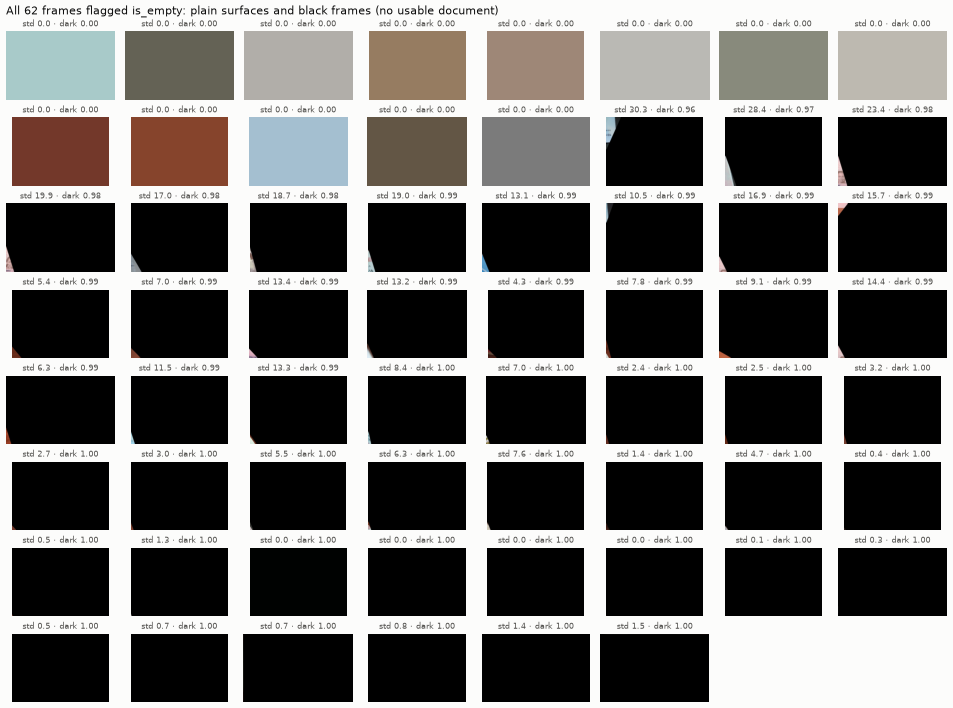

In [12]:
# Phase 2.1: flag video frames that show no document (failed crops in the dataset).
manifest = manifest.join(data.flag_blank_frames(manifest))
flagged = manifest[manifest["is_empty"]]
kept = manifest[~manifest["is_empty"]]
print(f"rule: grey std < {config.BLANK_STD_MAX:.0f} OR more than {config.BLANK_DARK_SHARE_MIN:.0%} of pixels darker than "
      f"{config.BLANK_DARK_LEVEL} (on a {config.BLANK_THUMBNAIL[0]}x{config.BLANK_THUMBNAIL[1]} greyscale thumbnail)")
print(f"empty frames: {len(flagged)} of {len(manifest):,} ({len(flagged) / len(manifest):.2%}), "
      f"from {flagged['doc_id'].nunique()} videos")
display(flagged.groupby(["split", "source", "label"]).size().rename("empty frames").to_frame())
black = flagged["dark_share"] > config.BLANK_DARK_SHARE_MIN
print("calibration margins:")
print(f"  dark-pixel share: flagged black frames >= {flagged.loc[black, 'dark_share'].min():.3f} | kept frames <= {kept['dark_share'].max():.3f}")
print(f"  grey std: flagged flat frames <= {flagged.loc[~black, 'pixel_std'].max():.2f} | kept frames >= {kept['pixel_std'].min():.2f}")

# Contact sheet of every flagged frame, for visual verification.
cols = 8
rows = int(np.ceil(len(flagged) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 1.5), dpi=60, facecolor="#fcfcfb")
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, flagged.sort_values(["dark_share", "pixel_std"]).itertuples()):
    with Image.open(ROOT / row.cache_path) as image:
        ax.imshow(np.asarray(image))
    ax.set_title(f"std {row.pixel_std:.1f} · dark {row.dark_share:.2f}", fontsize=9, color="#52514e")
fig.suptitle(f"All {len(flagged)} frames flagged is_empty: plain surfaces and black frames (no usable document)",
             x=0.01, ha="left", color="#0b0b0b", fontsize=13)
fig.tight_layout()
fig.savefig(REPORT_DIR / "blank_frames.png", dpi=80, facecolor="#fcfcfb")
plt.show()

**Step 6b — blank video frames (Phase 2.1).** While the document classifier was evaluated (Phase 3A), some video
frames turned out to show no document at all: the dataset's automatic crop missed the card and left a black frame
(sometimes with a sliver of the card in one corner) or a plain surface. Such frames carry no information about the
document type or about forgery, so they are flagged `is_empty` and excluded from forgery training and evaluation.

The rule works on a 64 × 40 greyscale thumbnail, which averages away JPEG noise: a frame is empty if its grey levels
hardly vary (standard deviation below 3, i.e. a flat colour) or if more than 90 % of its pixels are near-black
(grey value below 20). It was calibrated by inspecting every flagged frame (sheet above) and the closest frames that
are not flagged, and the margins are wide on both measures. Every flagged black frame has at least 96 % dark pixels,
while no kept frame has more than 62 %; those are documents partly outside the camera view, and they are kept. The
flat frames have a standard deviation of 0, while the dimmest kept documents still reach 5.2.

Result: **62 frames (0.44 %) are empty, all genuine video frames from 41 videos: 37 in train, 9 in validation and
16 in test.** No template and no forged frame is affected.

In [13]:
table = table.merge(manifest[["image_path", "cache_path", "orig_width", "orig_height", "is_empty"]],
                    on="image_path", how="left")
for check in data.check_leakage(manifest_full=table, manifest=manifest):
    print("PASS:", check)

PASS: every row has a split, and no image appears twice
PASS: no group_id appears in more than one split
PASS: every fake is in the same split as its src document (and its second_src)
PASS: all 76,259 image_path files and 14,027 cache_path files exist
PASS: test split contains all 10 document types


**Step 7 — leakage checks.** These are `assert` statements: if any of them fails, the notebook stops with an error
instead of saving a flawed split. All pass:
- no group appears in more than one split;
- every forgery is in the same split as its source document and as its donor;
- every original image and every cached copy exists on disk;
- the test split contains all 10 document types.

The manifests are written only after these checks have passed (next cells).

In [14]:
# Phase 2.1 safety check: the split must be exactly the one every model so far was trained on.
for path, current in ((config.MANIFEST_CSV, manifest), (config.MANIFEST_FULL_CSV, table)):
    if path.exists():
        n = data.assert_splits_unchanged(pd.read_csv(path, usecols=["image_path", "split"]), current)
        print(f"PASS: all {n:,} rows keep their split compared with the existing {path.name}")
    else:
        print(f"{path.name} does not exist yet (first run): nothing to compare")

PASS: all 14,027 rows keep their split compared with the existing manifest.csv
PASS: all 76,259 rows keep their split compared with the existing manifest_full.csv


**Split unchanged.** Before the manifests are overwritten, the new split is compared row by row with the files saved
by the previous run: the set of images and every image's split are identical. Adding the `is_empty` flag therefore
changes nothing for the models trained so far; the document classifier (Phase 3A) used exactly this split.

In [15]:
COLUMNS = ["image_path", "cache_path", "source", "label", "split", "group_id", "doc_type", "doc_id", "fake_name",
           "ctype", "altered_field", "second_src", "second_field", "frame", "orig_width", "orig_height", "is_empty"]
table[COLUMNS + ["in_sample"]].to_csv(config.MANIFEST_FULL_CSV, index=False)
manifest[COLUMNS].to_csv(config.MANIFEST_CSV, index=False)
for path in (config.MANIFEST_FULL_CSV, config.MANIFEST_CSV):
    shape = pd.read_csv(path, low_memory=False).shape
    print(f"{path.relative_to(ROOT)}: {shape[0]:,} rows x {shape[1]} columns, {path.stat().st_size / 1e6:.1f} MB")
display(manifest[COLUMNS].head(3))

data/processed/manifest_full.csv: 76,259 rows x 18 columns, 13.3 MB
data/processed/manifest.csv: 14,027 rows x 17 columns, 3.6 MB


,image_path,cache_path,source,label,split,group_id,doc_type,doc_id,fake_name,ctype,altered_field,second_src,second_field,frame,orig_width,orig_height,is_empty
0,data/interim/templates/Images/reals/alb_id_00.jpg,data/processed/images/templates/Images/reals/a...,template,0,train,alb_id_00,alb_id,alb_id_00,NaN,NaN,NaN,NaN,NaN,<NA>,2167,1360,False
1,data/interim/templates/Images/reals/alb_id_01.jpg,data/processed/images/templates/Images/reals/a...,template,0,train,alb_id_01,alb_id,alb_id_01,NaN,NaN,NaN,NaN,NaN,<NA>,2167,1360,False
2,data/interim/templates/Images/reals/alb_id_02.jpg,data/processed/images/templates/Images/reals/a...,template,0,train,alb_id_02,alb_id,alb_id_02,NaN,NaN,NaN,NaN,NaN,<NA>,2167,1360,False


**Saved manifests.** `manifest_full.csv` keeps all 76,259 images with their group, split and `in_sample` flag;
`manifest.csv` holds the 14,027 training images, each with the path to its cached copy and its `is_empty` flag
(`is_empty` is blank in `manifest_full.csv` for images outside the training sample, which are not cached and
therefore not checked). Every later notebook and service reads `manifest.csv`, so all models use exactly this
split. Reading both files back gives the expected numbers of rows and columns.

In [16]:
label_name = manifest["label"].map({0: "genuine", 1: "forged"})
counts = pd.crosstab(manifest["split"], [label_name, manifest["source"]], margins=True, margins_name="total")
counts = counts.loc[["train", "val", "test", "total"]]
counts.to_csv(REPORT_DIR / "counts_split_label_source.csv")
display(counts)

counts_type = pd.crosstab(manifest["doc_type"], manifest["split"], margins=True, margins_name="total")
counts_type = counts_type[["train", "val", "test", "total"]]
counts_type.to_csv(REPORT_DIR / "counts_split_doctype.csv")
display(counts_type)

label  forged          genuine           total
source   clip template    clip template       
split                                         
train    2776      853    5616      702   9947
val       589      179    1200      150   2118
test      440      190    1184      148   1962
total    3805     1222    8000     1000  14027

split,train,val,test,total
doc_type,,,,
alb_id,957,180,205,1342
aze_passport,964,186,254,1404
esp_id,1223,190,238,1651
est_id,947,179,214,1340
fin_id,989,193,159,1341
grc_passport,992,270,139,1401
lva_passport,965,213,224,1402
rus_internalpassport,967,256,182,1405
srb_passport,1024,233,143,1400


**Image counts per split.** The first table splits the training images by label and source, the second by document
type. Train / validation / test hold **9,947 / 2,118 / 1,962 images** (70.9 / 15.1 / 14.0 %). Video frames make up
most of the data, because each genuine document contributes 8 frames but only 1 template. Per document type the
splits are similar but not identical in size, because whole groups are assigned and groups differ in how many
forgeries they contain.

In [17]:
balance = manifest.groupby("split")["label"].agg(genuine=lambda s: int((s == 0).sum()),
                                                 forged=lambda s: int((s == 1).sum())).loc[["train", "val", "test"]]
balance["genuine_per_forged"] = (balance["genuine"] / balance["forged"]).round(2)
balance["forged_share"] = (balance["forged"] / (balance["genuine"] + balance["forged"])).round(3)
balance.to_csv(REPORT_DIR / "class_ratio_per_split.csv")
display(balance)

# "Balanced" class weights from the TRAINING split only: weight = total / (2 * count of the class).
train_counts = balance.loc["train", ["genuine", "forged"]]
weights = {"0": round(float(train_counts.sum() / (2 * train_counts["genuine"])), 4),
           "1": round(float(train_counts.sum() / (2 * train_counts["forged"])), 4)}
(REPORT_DIR / "class_weights_train.json").write_text(json.dumps(weights, indent=2))
print("class weights (0 = genuine, 1 = forged):", weights)
forged_videos = manifest[(manifest["source"] == "clip") & (manifest["label"] == 1)].drop_duplicates("fake_name")
print("forged videos per split:", forged_videos["split"].value_counts()[["train", "val", "test"]].to_dict())

,genuine,forged,genuine_per_forged,forged_share
split,,,,
train,6318,3629,1.74,0.365
val,1350,768,1.76,0.363
test,1332,630,2.11,0.321


class weights (0 = genuine, 1 = forged): {'0': 0.7872, '1': 1.3705}
forged videos per split: {'train': 139, 'val': 30, 'test': 22}


**Class balance.** Genuine images outnumber forged ones about **1.7 : 1 in train and validation (36 % forged) and
2.1 : 1 in test (32 % forged)**. Test has fewer forgeries because the split balances document types, not labels, and
it happened to receive only 22 of the 191 forged videos (12 %) instead of about 15 %. The gap is small, but it
matters when reporting: precision and PR-AUC depend on how common the forged class is, so test results must be
compared with a 32 % baseline, not 36 %.

For Phase 3, class weights are computed from the **training split only** with the standard "balanced" formula,
*weight = total / (2 × class count)*: **0.79 for genuine and 1.37 for forged**, saved to
`reports/phase2/class_weights_train.json`. During training each forged image's error then counts about 1.7 times as
much as a genuine one's, so the model cannot score well by simply favouring "genuine".

In [18]:
template_fakes = manifest[(manifest["source"] == "template") & (manifest["label"] == 1)]
manifest_fakes = manifest[manifest["label"] == 1]
ctype_table = pd.crosstab(manifest_fakes["ctype"], manifest_fakes["split"])[["train", "val", "test"]]
ctype_table.insert(0, "distinct_forgeries", template_fakes["ctype"].value_counts())
ctype_table.to_csv(REPORT_DIR / "ctype_distribution.csv")
display(ctype_table)

field_table = pd.crosstab(template_fakes["altered_field"], template_fakes["ctype"])
field_table["total"] = field_table.sum(axis=1)
field_table = field_table.sort_values("total", ascending=False)
field_table.to_csv(REPORT_DIR / "altered_field_distribution.csv")
print(f"{len(field_table)} distinct altered fields; top 10:")
display(field_table.head(10))

# How big is the edited region? Box from the ground truth, relative to the whole image.
boxes = gt.set_index(["doc_id", "field_name"])[["w", "h"]]
sized = template_fakes.join(boxes, on=["doc_id", "altered_field"])
area_share = sized["w"] * sized["h"] / (sized["orig_width"] * sized["orig_height"])
height_in_cache = sized["h"] * config.RESIZE_LONGEST / sized[["orig_width", "orig_height"]].max(axis=1)
print(f"altered box: median {area_share.median():.1%} of the image area "
      f"(90% of boxes below {area_share.quantile(0.9):.1%}); median height in the 512 px cache: {height_in_cache.median():.0f} px")

split,distinct_forgeries,train,val,test
ctype,,,,
Crop_and_Replace,145,525,82,98
Inpaint_and_Rewrite,1077,3104,686,532


41 distinct altered fields; top 10:


ctype,Crop_and_Replace,Inpaint_and_Rewrite,total
altered_field,,,
gender,9,104,113
surname,23,88,111
name,20,91,111
number,10,94,104
expiry_date,6,81,87
nationality,8,74,82
birth_date,9,57,66
issue_date,4,56,60
id_number,4,53,57


altered box: median 0.4% of the image area (90% of boxes below 1.0%); median height in the 512 px cache: 11 px


**Forgery methods and altered fields.** Of the 1,222 distinct forgeries, **1,077 (88 %) are Inpaint_and_Rewrite**
(a field's text is erased and rewritten) and **145 (12 %) are Crop_and_Replace** (a field is cut from another
document of the same type and pasted in). The edits are spread over 41 field names; the most common are gender,
surname, name and the document number, each about 9 % of the forgeries. Field counts use the distinct forgeries
(templates), because a forged video repeats its template's edit in up to 20 frames.

The edited region is tiny: the median altered box covers **0.4 % of the image** (90 % of boxes cover less than
1 %) and is only **about 11 px tall in the 512 px cache**. This is the key fact for Phase 3. The forgery signal is a
small patch of text, so the detector should use the full 512 px cached images; shrinking them to 300 px would leave
the edited text only about 6 px tall. If the detector struggles, a higher-resolution cache or crops around the text
are the next step. Grad-CAM should then show whether the model looks at that patch.

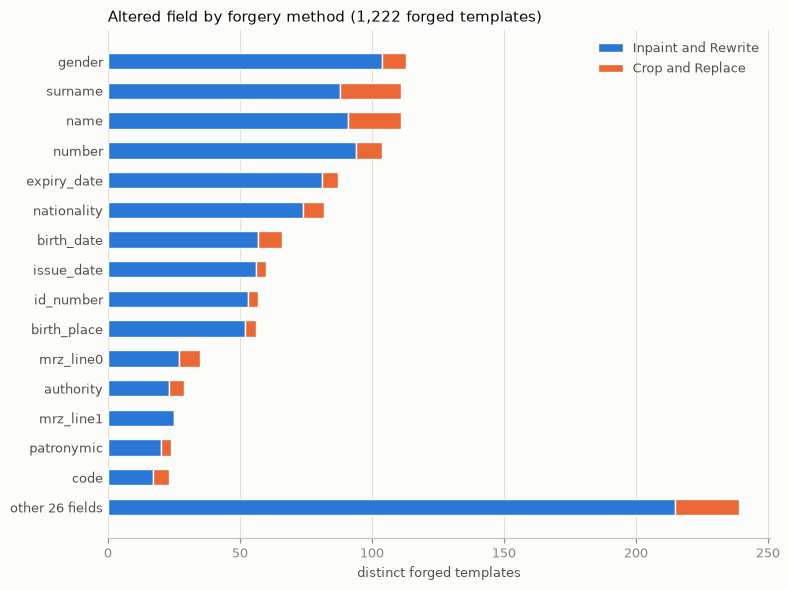

In [19]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = {"Inpaint_and_Rewrite": "#2a78d6", "Crop_and_Replace": "#eb6834"}  # validated 2-colour palette

top = field_table.head(15)[list(SERIES)]
others = field_table.iloc[15:][list(SERIES)].sum().rename(f"other {len(field_table) - 15} fields")
plot_data = pd.concat([top, others.to_frame().T])

fig, ax = plt.subplots(figsize=(8, 6), dpi=100, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
y = np.arange(len(plot_data))[::-1]  # most common field at the top
left = np.zeros(len(plot_data))
for ctype, color in SERIES.items():
    ax.barh(y, plot_data[ctype], left=left, height=0.55, color=color, edgecolor=SURFACE, linewidth=1,
            label=ctype.replace("_", " "))
    left += plot_data[ctype].to_numpy()
ax.set_yticks(y, plot_data.index, color=INK_2, fontsize=9)
ax.tick_params(axis="x", colors=MUTED, labelsize=9)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.set_xlabel("distinct forged templates", color=INK_2, fontsize=9)
ax.set_title("Altered field by forgery method (1,222 forged templates)", loc="left", color=INK, fontsize=11)
ax.legend(frameon=False, loc="upper right", labelcolor=INK_2, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT_DIR / "altered_fields_by_ctype.png", dpi=150, facecolor=SURFACE)
plt.show()

**Chart.** The 15 most often altered fields plus the remaining fields combined, split by forgery method (blue =
Inpaint_and_Rewrite, orange = Crop_and_Replace). Edits concentrate on a handful of personal-data fields: gender,
surname, name, the document number and the dates. Crop_and_Replace is the minority method in almost every field
(19 of the 41 fields never use it), and among the common fields its share is highest for surname and name (about
20 %), where text is swapped in from another person's card. Saved as `reports/phase2/altered_fields_by_ctype.png`.

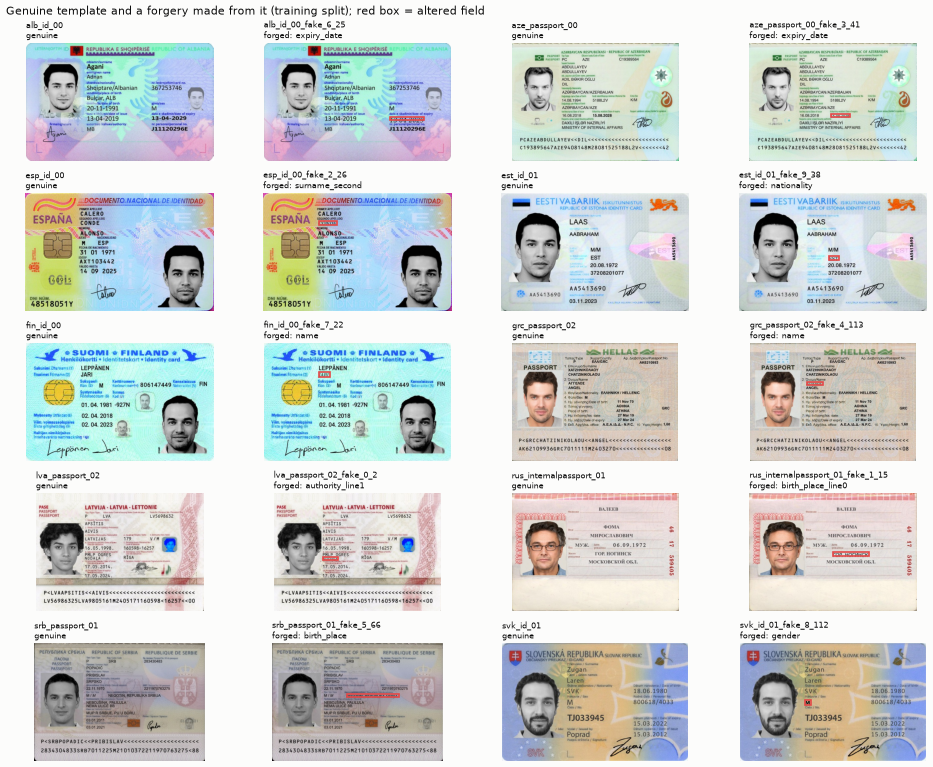

In [20]:
BOX = "#e34948"
train_fakes = manifest[(manifest["split"] == "train") & (manifest["source"] == "template")
                       & (manifest["ctype"] == "Inpaint_and_Rewrite")]
examples = train_fakes.sort_values("fake_name").groupby("doc_type").head(1).sort_values("doc_type")
genuine = manifest[(manifest["source"] == "template") & (manifest["label"] == 0)].set_index("doc_id")
box_of = gt.set_index(["doc_id", "field_name"])[["x", "y", "w", "h"]]

# dpi=60 keeps the copy embedded in the notebook small; the saved file uses dpi=100.
fig, axes = plt.subplots(5, 4, figsize=(16, 13), dpi=60, facecolor=SURFACE)
for ax_genuine, ax_forged, (_, fake) in zip(axes.flat[0::2], axes.flat[1::2], examples.iterrows()):
    for ax, row, title in [(ax_genuine, genuine.loc[fake["doc_id"]], f"{fake['doc_id']}\ngenuine"),
                           (ax_forged, fake, f"{fake['fake_name']}\nforged: {fake['altered_field']}")]:
        with Image.open(ROOT / row["cache_path"]) as image:
            ax.imshow(np.asarray(image))
            scale = image.width / row["orig_width"]  # original pixels -> cached pixels
        ax.set_title(title, loc="left", fontsize=10, color=INK)
        ax.axis("off")
    x, y, w, h = box_of.loc[(fake["doc_id"], fake["altered_field"])]
    ax_forged.add_patch(Rectangle((x * scale, y * scale), w * scale, h * scale, fill=False, edgecolor=BOX, linewidth=2))
fig.suptitle("Genuine template and a forgery made from it (training split); red box = altered field",
             x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(REPORT_DIR / "sample_grid.png", dpi=100, facecolor=SURFACE)
plt.show()

**Sample grid.** One document per type from the training split: the genuine template next to a forgery made from it,
with the altered field outlined using its box from `fields_ground_truth.csv`, scaled to the cached image. The pairs
look almost identical: the edits are small, local and well blended, which is what makes forgery detection hard. The
red boxes sit on the edited text, which also confirms that the annotation boxes line up with the cached images.
Saved as `reports/phase2/sample_grid.png`.

In [21]:
print(f"notebook run time: {(time.perf_counter() - notebook_start) / 60:.1f} min (of which image cache {cache_seconds / 60:.1f} min)")
for path in sorted([config.MANIFEST_FULL_CSV, config.MANIFEST_CSV, config.FIELDS_GT_CSV, *REPORT_DIR.iterdir()]):
    print(f"  {path.relative_to(ROOT)}  ({path.stat().st_size / 1e3:,.0f} KB)")

notebook run time: 0.3 min (of which image cache 0.0 min)
  data/processed/fields_ground_truth.csv  (794 KB)
  data/processed/manifest.csv  (3,644 KB)
  data/processed/manifest_full.csv  (13,278 KB)
  reports/phase2/altered_field_distribution.csv  (1 KB)
  reports/phase2/altered_fields_by_ctype.png  (61 KB)
  reports/phase2/blank_frames.png  (57 KB)
  reports/phase2/class_ratio_per_split.csv  (0 KB)
  reports/phase2/class_weights_train.json  (0 KB)
  reports/phase2/counts_split_doctype.csv  (0 KB)
  reports/phase2/counts_split_label_source.csv  (0 KB)
  reports/phase2/ctype_distribution.csv  (0 KB)
  reports/phase2/sample_grid.png  (2,466 KB)


**Summary of Phase 2.**
- 76,259 images parsed from four sources into one table; the training manifest keeps 14,027 of them (all templates
  plus evenly spaced clip frames).
- 927 document groups; no group spans two document types. Split by group and stratified by type: 649 / 139 / 139
  groups, 9,947 / 2,118 / 1,962 images. All leakage checks pass.
- Two data issues found and fixed: 72 forgery filenames name the donor rather than the source (`doc_id` now comes
  from the JSON), and half of the genuine templates are CMYK (the cache converts everything to RGB).
- Class weights for Phase 3 (train only): genuine 0.79, forged 1.37. Test has a slightly lower forged share
  (32 % vs 36 %), to keep in mind when reading precision and PR-AUC.
- Forgeries are tiny local edits (median 0.4 % of the image, about 11 px tall at 512 px), so the forgery detector
  should work at the full cache resolution.
- Phase 2.1: 62 video frames that show no document (failed crops in the dataset) are flagged `is_empty`; the split
  is unchanged.

**Next (Phase 3):** train the document-type classifier and the forgery detector on `manifest.csv` with the cached
images and these class weights. The test split stays untouched until the final evaluation.